In [1]:
# All imports

import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.path import Path
from scipy.stats import weibull_min
from tqdm.auto import tqdm

from py_wake.site import UniformWeibullSite
from py_wake.wind_farm_models import All2AllIterative
from py_wake.deficit_models import BastankhahGaussianDeficit
from py_wake.superposition_models import SquaredSum
from py_wake.utils.gradients import fd
from py_wake.wind_turbines.power_ct_functions import PowerCtTabular
from py_wake.wind_turbines import WindTurbine, WindTurbines

from topfarm._topfarm import TopFarmProblem
from topfarm.cost_models.py_wake_wrapper import PyWakeAEPCostModelComponent
from topfarm.constraint_components.boundary import XYBoundaryConstraint
from topfarm.constraint_components.spacing import SpacingConstraint
from topfarm.easy_drivers import EasyScipyOptimizeDriver

/Users/aronwalter/miniconda3/envs/pywake/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Creating custom turbine for Vestas V136-4.5
import numpy as np

# Wind speed (m/s)[cite: 1]
u_1 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 1]
ct_1 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.873, 0.847, 0.845, 0.843, 
    0.844, 0.840, 0.834, 0.828, 0.821, 0.814, 0.816, 0.799, 0.746, 0.675, 
    0.608, 0.552, 0.499, 0.448, 0.396, 0.346, 0.303, 0.269, 0.239, 0.213, 
    0.191, 0.172, 0.156, 0.142, 0.130, 0.119, 0.110, 0.102, 0.094, 0.087, 
    0.081, 0.075, 0.071, 0.067, 0.063, 0.059, 0.055, 0.051, 0.048, 0.044, 
    0.041, 0.039, 0.036, 0.033, 0.031, 0.029, 0.026, 0.024, 0.021, 0.019, 0.017
])

# Power (kW)[cite: 1] (Multiply by 1000 if your model requires Watts)
power_1 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 55.0, 130.0, 220.0, 331.0, 
    471.0, 639.0, 841.0, 1081.0, 1362.0, 1681.0, 2042.0, 2441.0, 2845.0, 3214.0, 
    3552.0, 3867.0, 4128.0, 4328.0, 4442.0, 4486.0, 4498.0, 4498.0, 4500.0, 4500.0, 
    4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 4500.0, 
    4500.0, 4500.0, 4500.0, 4498.0, 4473.0, 4421.0, 4336.0, 4230.0, 4131.0, 4044.0, 
    3952.0, 3858.0, 3756.0, 3620.0, 3456.0, 3261.0, 3033.0, 2789.0, 2548.0, 2548.0, 2548.0
])

# 2. Define your target hub heights
hub_heights = [82,112]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines = {}
for hh in hub_heights:
    name = f"v136_45_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=136,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_1, power_1, 'kW', ct_1)
    )
    
    # Store in a dictionary for easy iteration
    turbines[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

In [3]:
# Creating custom turbine for Nordex_N149_5
# Wind speed (m/s)[cite: 2]
u_2 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 2]
ct_2 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.835, 0.825, 0.815, 0.806, 
    0.798, 0.793, 0.790, 0.788, 0.788, 0.784, 0.767, 0.742, 0.710, 0.671, 
    0.627, 0.579, 0.531, 0.484, 0.437, 0.392, 0.352, 0.316, 0.284, 0.255, 
    0.229, 0.206, 0.186, 0.169, 0.154, 0.141, 0.130, 0.120, 0.112, 0.104, 
    0.098, 0.093, 0.088, 0.084, 0.081, 0.075, 0.069, 0.064, 0.059, 0.055, 
    0.051, 0.047, 0.044, 0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0
])

# Power (kW)[cite: 2] (Multiply by 1000 if your PyWake setup requires Watts)
power_2 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 29.0, 113.0, 233.0, 383.0, 
    561.0, 773.0, 1023.0, 1317.0, 1658.0, 2050.0, 2497.0, 2988.0, 3496.0, 4001.0, 
    4477.0, 4851.0, 5122.0, 5309.0, 5427.0, 5487.0, 5500.0, 5500.0, 5500.0, 5500.0, 
    5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 5500.0, 
    5500.0, 5500.0, 5500.0, 5500.0, 5469.0, 5387.0, 5278.0, 5147.0, 5039.0, 4891.0, 
    4782.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
])

# 2. Define your target hub heights
hub_heights_2 = [105, 135, 164]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines_2 = {}
for hh in hub_heights_2:
    name = f"Nordex_N149_5_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=149,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_2, power_2, 'kW', ct_2)
    )
    
    # Store in a dictionary for easy iteration
    turbines_2[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

In [4]:
# Creating custom turbine for v162_6
# Wind speed (m/s)[cite: 2]
u_3 = np.array([
    0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 
    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 
    10.0, 10.5, 11.0, 11.5, 12.0, 12.5, 13.0, 13.5, 14.0, 14.5, 
    15.0, 15.5, 16.0, 16.5, 17.0, 17.5, 18.0, 18.5, 19.0, 19.5, 
    20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0, 23.5, 24.0, 24.5, 
    25.0, 25.5, 26.0, 26.5, 27.0, 27.5, 28.0, 28.5, 29.0, 29.5, 30.0
])

# Thrust coefficient (ct)[cite: 2]
ct_3 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.908, 0.882, 0.853, 0.837, 
    0.820, 0.814, 0.812, 0.810, 0.807, 0.804, 0.800, 0.793, 0.763, 0.701, 
    0.635, 0.559, 0.484, 0.413, 0.356, 0.310, 0.273, 0.242, 0.216, 0.193, 
    0.174, 0.158, 0.144, 0.131, 0.120, 0.111, 0.100, 0.089, 0.079, 0.070, 
    0.062, 0.055, 0.048, 0.043, 0.038, 0.033, 0.029, 0.025, 0.022, 0.0, 
    0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0
])

# Power (kW)[cite: 2] (Multiply by 1000 if your PyWake setup requires Watts)
power_3 = np.array([
    0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 32.0, 150.0, 292.0, 467.0, 
    676.0, 927.0, 1229.0, 1584.0, 2000.0, 2476.0, 3017.0, 3624.0, 4264.0, 4859.0, 
    5380.0, 5734.0, 5932.0, 5983.0, 5998.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 
    6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 6000.0, 5846.0, 5581.0, 
    5360.0, 5128.0, 4844.0, 4555.0, 4268.0, 3985.0, 3690.0, 3383.0, 3102.0, 2801.0, 
    2479.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
])

# 2. Define your target hub heights
hub_heights_3 = [119, 149, 166]

# 3. Create them dynamically and inject them directly into your workspace variables
turbines_3 = {}
for hh in hub_heights_3:
    name = f"v162_6_{hh}"
    
    # Create the turbine object
    turbine_obj = WindTurbine(
        name=name,
        diameter=162,
        hub_height=hh,
        powerCtFunction=PowerCtTabular(u_3, power_3, 'kW', ct_3)
    )
    
    # Store in a dictionary for easy iteration
    turbines_3[name] = turbine_obj
    
    # OPTIONAL: This dynamically creates variables named `v126_345_117`, `v126_345_137`, etc., 
    # so you can type them directly into your cells later!
    locals()[name] = turbine_obj

In [5]:
# This converts the coordinates of out eligible area into x-y coordinates
# Assumes that the origin is at the bottom left of the shape
import numpy as np
from pyproj import Proj

# Paste your extracted coordinate string here directly from the KML
coords_text = """
1.206860519027202,51.36446385128804,0 1.228540535625071,51.36084646145472,0 1.231326914666149,51.36188554554997,0 1.230900428385338,51.36335221424344,0 1.231327805526934,51.36484423631089,0 1.232271635958224,51.36622022749638,0 1.234157153928741,51.36720473911184,0 1.235699875038621,51.36754714218748,0 1.237311169556172,51.36773970677682,0 1.23816843336801,51.36904525549213,0 1.23998567737952,51.37011530661318,0 1.242180078810307,51.37080004683563,0 1.244278951540922,51.37099084556765,0 1.257965756297754,51.37142367570682,0 1.256980499819131,51.37685128614747,0 1.25101941585005,51.37685381922977,0 1.224173520164562,51.3787160209091,0 1.224263858984787,51.37828483960372,0 1.225127525628988,51.37738319886369,0 1.225643005910668,51.3759615509838,0 1.225426984561819,51.37490328765479,0 1.225044701109166,51.37401101384313,0 1.22547755707124,51.37160360959665,0 1.20754064599127,51.36984418480619,0 1.205743544487601,51.36788013238516,0 1.206860519027202,51.36446385128804,0 
"""

# 1. Parse longitude and latitude values
raw_coords = [list(map(float, c.split(',')[:2])) for c in coords_text.strip().split()]
lons = np.array([c[0] for c in raw_coords])
lats = np.array([c[1] for c in raw_coords])

# 2. Convert Lat/Lon to UTM meters (Zone 31N covers Kent, UK)
proj = Proj(proj='utm', zone=31, ellps='WGS84', datum='WGS84')
x_utm, y_utm = proj(lons, lats)

# 3. Shift coordinates so the bottom-left corner (min x, min y) is (0, 0)
x_origin = x_utm.min()
y_origin = y_utm.min()

site_boundary_vertices = np.column_stack((x_utm - x_origin, y_utm - y_origin))

print("Generated Site Boundary Vertices (meters):\n", site_boundary_vertices)


Generated Site Boundary Vertices (meters):
 [[  68.45770514  438.93300351]
 [1567.90857637    0.        ]
 [1764.67378761  110.86284197]
 [1738.91865294  274.67123971]
 [1772.67145429  439.86507053]
 [1842.0607912   591.2897853 ]
 [1975.94537651  697.60419361]
 [2084.24575496  733.09415252]
 [2196.91712117  751.80971222]
 [2260.07640035  895.55163103]
 [2389.42056276 1011.50279578]
 [2543.98221539 1083.9814217 ]
 [2690.57524461 1101.69788268]
 [3644.33970267 1127.10586596]
 [3590.11366662 1732.28380318]
 [3175.27340448 1742.44520137]
 [1312.0189506  1994.43238928]
 [1317.14421963 1946.33306988]
 [1374.81957794 1844.61585406]
 [1406.86657292 1685.6613361 ]
 [1388.98447867 1568.3471465 ]
 [1359.9772697  1469.77104965]
 [1383.62333263 1201.34044602]
 [ 130.42779462 1036.0622954 ]
 [   0.          820.72138312]
 [  68.45770514  438.93300351]]


In [6]:
FILE_NAME, SHEET_NAME, DIR_COL = '9 Manston 2008 new.xlsx', 'MANSTON', 'Col_F'

# Columns E:I and K:P, skipping J because it duplicates I
raw = pd.read_excel(FILE_NAME, sheet_name=SHEET_NAME, engine='openpyxl',
                    usecols="E:I,K:P", header=None)
raw.columns = ['Col_E', 'Col_F', 'Col_G',
               'Col_H', 'Col_I',                 # Turbine 1: hub height LOW, MID (= HIGH)
               'Col_K', 'Col_L', 'Col_M',        # Turbine 2: LOW, MID, HIGH
               'Col_N', 'Col_O', 'Col_P']        # Turbine 3: LOW, MID, HIGH

def weibull_site(speed_col, ti=0.1):
    df = raw[[speed_col, DIR_COL]].copy()
    for c in (speed_col, DIR_COL):
        df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.'), errors='coerce')
    df = df.dropna()
    speed = df[speed_col].values * 0.514444                      # knots -> m/s
    sector = np.round(df[DIR_COL].values / 30.0).astype(int) % 12
    p_wd, a, k = [], [], []
    for i in range(12):
        s = speed[sector == i]
        pos = s[s > 0.1]
        if len(s) == 0:
            f, A, K = 0.0, 0.0, 1.0
        elif len(np.unique(pos)) < 2:
            f, A, K = len(s) / len(df), (pos[0] if len(pos) else 0.0), 1.0
        else:
            K, _, A = weibull_min.fit(pos, floc=0)
            f = len(s) / len(df)
        p_wd.append(round(f, 4)); a.append(round(A, 2)); k.append(round(K, 2))
    return UniformWeibullSite(p_wd=p_wd, a=a, k=k, ti=ti)

In [7]:
all_turbines = {**turbines, **turbines_2, **turbines_3}    # the 8 individual turbine objects

speed_col = {
    'v136_45_82':        'Col_H',
    'v136_45_112':       'Col_I',
    'Nordex_N149_5_105': 'Col_K',
    'Nordex_N149_5_135': 'Col_L',
    'Nordex_N149_5_164': 'Col_M',
    'v162_6_119':        'Col_N',
    'v162_6_149':        'Col_O',
    'v162_6_166':        'Col_P',
}
assert set(speed_col) == set(all_turbines), "registry and speed_col names don't match"

In [8]:
from matplotlib.path import Path

def initial_layout(n_wt, vertices, min_spacing, seed=0, max_tries=50000):
    """Random points inside the boundary, all at least min_spacing apart."""
    rng = np.random.default_rng(seed)
    vertices = np.asarray(vertices, dtype=float)
    poly = Path(vertices)
    lo, hi = vertices.min(axis=0), vertices.max(axis=0)
    pts = []
    for _ in range(max_tries):
        p = rng.uniform(lo, hi)
        if not poly.contains_point(p):
            continue
        if pts and np.hypot(*(np.array(pts) - p).T).min() < min_spacing:
            continue
        pts.append(p)
        if len(pts) == n_wt:
            return np.array(pts).T          # returns x, y
    raise RuntimeError(f"Could not place {n_wt} turbines with {min_spacing:.0f} m spacing "
                       f"inside the boundary. Reduce spacing or turbine count.")

In [9]:
def get_topfarmProblem(wfm, x0, y0, grad_method, maxiter, n_cpu, vertices):
    return TopFarmProblem(
        design_vars={'x': x0, 'y': y0},
        cost_comp=PyWakeAEPCostModelComponent(
            windFarmModel=wfm, n_wt=len(x0),
            grad_method=grad_method, n_cpu=n_cpu,
            wd=wfm.site.default_wd, ws=wfm.site.default_ws),
        driver=EasyScipyOptimizeDriver(maxiter=maxiter),
        constraints=[XYBoundaryConstraint(vertices, boundary_type='polygon'),
             SpacingConstraint(min_spacing=2 * wfm.windTurbines.diameter())])

In [10]:
def hex_layout(n_wt, vertices, spacings, seed=0, n_trials=300):
    rng = np.random.default_rng(seed)
    V = np.asarray(vertices, float); poly = Path(V)
    centre = (V.min(0) + V.max(0)) / 2
    for s in spacings:
        m = int(np.hypot(*(V.max(0) - V.min(0))) / s) + 2
        i, j = np.meshgrid(np.arange(-m, m + 1), np.arange(-m, m + 1))
        g = np.c_[(s * (i + 0.5 * j)).ravel(), (s * np.sqrt(3) / 2 * j).ravel()]
        for _ in range(n_trials):
            th = rng.uniform(0, np.pi / 3)
            R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
            p = g @ R.T + centre + rng.uniform(-s, s, 2)
            p = p[poly.contains_points(p)]
            if len(p) >= n_wt:
                p = p[rng.choice(len(p), n_wt, replace=False)]
                return p[:, 0], p[:, 1], s
    raise RuntimeError("no feasible start layout")

def start_layout(n_wt, vertices, D, seed=0):
    try:
        return initial_layout(n_wt, vertices, 2.5 * D, seed=seed)
    except RuntimeError:
        x, y, _ = hex_layout(n_wt, vertices, np.arange(2.5, 2.049, -0.05) * D, seed=seed)
        return x, y

def sweep_turbine_numbers(wfm, vertices, n_list, maxiter=100, n_starts=1,
                          grad_method=fd, n_cpu=1):
    D = wfm.windTurbines.diameter()
    rows, layouts = [], {}
    for n_wt in tqdm(n_list):
        best = None
        for s in range(n_starts):
            try:
                x0, y0 = start_layout(n_wt, vertices, D, seed=s)
            except RuntimeError:
                continue                                   # no feasible start for this N
            tf = get_topfarmProblem(wfm, x0, y0, grad_method, maxiter, n_cpu, vertices)
            _, state, _ = tf.optimize(disp=False)
            x, y = state['x'], state['y']
            aep = wfm(x, y).aep().sum().item()
            if best is None or aep > best[0]:
                best = (aep, x, y, wfm(x0, y0).aep().sum().item())
        if best is None:
            rows.append({'n_wt': n_wt}); continue          # NaN row, shows as a gap in plots
        aep, x, y, aep_init = best
        aep_nowake = wfm(x, y).aep(with_wake_loss=False).sum().item()
        rows.append({'n_wt': n_wt, 'aep_initial_GWh': aep_init, 'aep_opt_GWh': aep,
                     'aep_per_turbine_GWh': aep / n_wt,
                     'wake_loss_%': 100 * (1 - aep / aep_nowake)})
        layouts[n_wt] = (x, y)
    return pd.DataFrame(rows), layouts

In [16]:
OUT = pathlib.Path('results'); PER = OUT / 'per_turbine'
PER.mkdir(parents=True, exist_ok=True)

def run_turbine(name, n_list, maxiter, vertices, n_starts=1):
    wt = all_turbines[name]
    wfm = All2AllIterative(site=weibull_site(speed_col[name]), windTurbines=wt,
                           wake_deficitModel=BastankhahGaussianDeficit(),
                           superpositionModel=SquaredSum())
    res, layouts = sweep_turbine_numbers(wfm, vertices, n_list, maxiter=maxiter, n_starts=n_starts)
    rated_MW = float(wt.power(15)) / 1e6
    res.insert(0, 'turbine', name)
    res.insert(1, 'diameter_m', wt.diameter())
    res.insert(2, 'hub_height_m', wt.hub_height())
    res.insert(3, 'rated_MW', rated_MW)
    res['capacity_factor'] = res['aep_opt_GWh'] / (res['n_wt'] * rated_MW * 8.76)
    return res, layouts

def run_all(n_list=range(5, 27, 3), maxiter=20, n_starts=1):
    for name in all_turbines:
        csv = PER / f'{name}.csv'
        if csv.exists():
            print(f'{name}: already done, skipping'); continue
        res, layouts = run_turbine(name, n_list, maxiter, site_boundary_vertices, n_starts)
        np.savez(PER / f'{name}_layouts.npz',
                 **{f'{ax}_{n}': v for n, (x, y) in layouts.items() for ax, v in (('x', x), ('y', y))})
        res.to_csv(csv, index=False)          # written last, so a CSV means the turbine finished
        print(f'{name}: saved')

run_all()    # test first with run_all(n_list=[5], maxiter=20), then delete the test CSVs

  0%|          | 0/8 [00:00<?, ?it/s]

INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000326 sec).
INFO: checking system...
INFO:     system check complete (0.000019 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000170 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000041 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000004 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000426 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000043 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000005 sec).
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000153 sec).
INFO: checking system...
INFO:     system check complete (0.000009 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000130 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check com

 12%|█▎        | 1/8 [00:06<00:42,  6.02s/it]

Iteration limit reached    (Exit mode 9)
            Current function value: -80.53018074999693
            Iterations: 20
            Function evaluations: 21
            Gradient evaluations: 21
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000188 sec).
INFO: checking system...
INFO:     system check complete (0.000014 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000104 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000056 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000011 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000407 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000057 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000006 sec).
INFO: checking

 25%|██▌       | 2/8 [00:19<01:04, 10.70s/it]

Iteration limit reached    (Exit mode 9)
            Current function value: -125.45016946905004
            Iterations: 20
            Function evaluations: 21
            Gradient evaluations: 21
Optimization FAILED.
Iteration limit reached
-----------------------------------
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000152 sec).
INFO: checking system...
INFO:     system check complete (0.000009 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000075 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000023 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000002 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000125 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000021 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000001 sec).
INFO: checkin

... (134 outputs left out)

 88%|████████▊ | 7/8 [08:32<01:57, 117.45s/it]

INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000168 sec).
INFO: checking system...
INFO:     system check complete (0.000010 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000086 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check complete (0.000023 sec).
INFO: checking missing_recorders...
INFO:     missing_recorders check complete (0.000002 sec).
INFO: checking unserializable_options...
INFO:     unserializable_options check complete (0.000148 sec).
INFO: checking comp_has_no_outputs...
INFO:     comp_has_no_outputs check complete (0.000022 sec).
INFO: checking auto_ivc_warnings...
INFO:     auto_ivc_warnings check complete (0.000001 sec).
INFO: checking out_of_order...
INFO:     out_of_order check complete (0.000095 sec).
INFO: checking system...
INFO:     system check complete (0.000006 sec).
INFO: checking solvers...
INFO:     solvers check complete (0.000070 sec).
INFO: checking dup_inputs...
INFO:     dup_inputs check com

100%|██████████| 8/8 [13:09<00:00, 98.63s/it] 

v162_6_166: saved


turbine  Nordex_N149_5_105  Nordex_N149_5_135  Nordex_N149_5_164  v136_45_112  \
n_wt                                                                            
5               104.178176         110.218805         114.909362    86.583323   
8               161.965640         171.500368         178.909936   135.066891   
11              217.803324         230.925809         241.148630   181.352365   
14              268.528636         285.151419         298.136333   226.820576   
17              311.862556         331.889856         347.581205   263.050901   
20              355.232243         378.803445         396.987000   298.471345   
23              395.960543         422.692219         443.774337   338.952849   
26              406.950512         435.989787         459.171731   373.810112   

turbine  v136_45_82  v162_6_119  v162_6_149  v162_6_166  
n_wt                                                     
5         80.530181  123.533138  129.391414  132.170896  
8        125.45

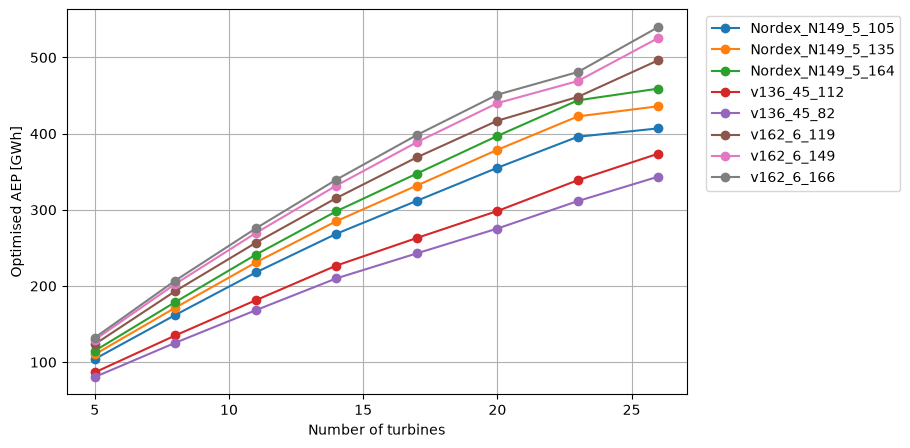

In [17]:
all_res = pd.concat([pd.read_csv(f) for f in sorted(PER.glob('*.csv'))], ignore_index=True)
all_res.to_csv(OUT / 'all_results.csv', index=False)
print(all_res.pivot(index='n_wt', columns='turbine', values='aep_opt_GWh'))

"""
# one graph per turbine type
for name, g in all_res.groupby('turbine', sort=False):
    fig, ax = plt.subplots()
    ax.plot(g['n_wt'], g['aep_opt_GWh'], 'o-')
    ax.set(xlabel='Number of turbines', ylabel='Optimised AEP [GWh]', title=name); ax.grid(True)
    fig.savefig(OUT / f'aep_vs_n_{name}.png', dpi=200, bbox_inches='tight')
    """

# all together
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_res.groupby('turbine', sort=False):
    ax.plot(g['n_wt'], g['aep_opt_GWh'], 'o-', label=name)
ax.set(xlabel='Number of turbines', ylabel='Optimised AEP [GWh]'); ax.grid(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(OUT / 'aep_vs_n_all.png', dpi=200, bbox_inches='tight')

           x_m          y_m
0  2305.186085  1468.046187
1  2031.822575  1897.085894
2  1113.943931   805.266416
3  1316.484154  1961.013958
4  1077.334510   277.085224
5  1733.768614   991.380238
6  3304.858701  1647.977214
7  1741.182846   260.270470
8   286.265609   616.127904


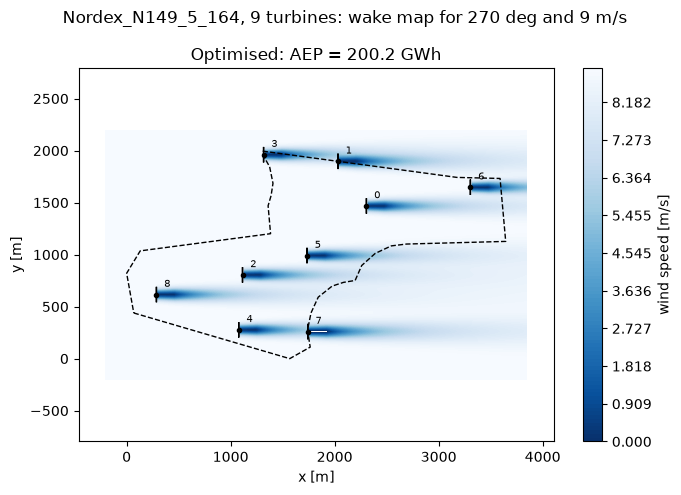

In [15]:
from py_wake.flow_map import XYGrid        # swap for HorizontalGrid if your version complains (same arguments)

def build_wfm(name):
    return All2AllIterative(site=weibull_site(speed_col[name]), windTurbines=all_turbines[name],
                            wake_deficitModel=BastankhahGaussianDeficit(),
                            superpositionModel=SquaredSum())

def load_layout(name, n_wt):
    d = np.load(PER / f'{name}_layouts.npz')
    return d[f'x_{n_wt}'], d[f'y_{n_wt}']

def plot_case(name, n_wt, wdir=270, wsp=9, compare=False):
    """Wake map of the optimised layout for one turbine type and turbine count."""
    wfm = build_wfm(name)
    layouts = [('Optimised', *load_layout(name, n_wt))]
    if compare:   # regenerates the starting layout (same seed as the sweep)
        x0, y0 = start_layout(n_wt, site_boundary_vertices, wfm.windTurbines.diameter(), seed=0)
        layouts.insert(0, ('Initial', x0, y0))

    bx, by = np.asarray(site_boundary_vertices).T
    grid = XYGrid(x=np.linspace(bx.min() - 200, bx.max() + 200, 300),
                  y=np.linspace(by.min() - 200, by.max() + 200, 200))
    levels = np.linspace(0, wsp, 100)

    fig, axes = plt.subplots(1, len(layouts), figsize=(7 * len(layouts), 5), sharey=True, squeeze=False)
    for ax, (label, x, y) in zip(axes[0], layouts):
        sim = wfm(x, y)
        sim.flow_map(grid=grid, wd=wdir, ws=wsp).plot_wake_map(ax=ax, levels=levels)
        ax.plot(np.append(bx, bx[0]), np.append(by, by[0]), 'k--', lw=1)    # site boundary
        ax.set_xlabel('x [m]')
        ax.set_title(f'{label}: AEP = {sim.aep().sum().item():.1f} GWh')
    axes[0][0].set_ylabel('y [m]')
    fig.suptitle(f'{name}, {n_wt} turbines: wake map for {wdir} deg and {wsp} m/s')
    plt.tight_layout()

    x, y = layouts[-1][1], layouts[-1][2]
    return pd.DataFrame({'x_m': x, 'y_m': y})        # optimised coordinates

coords = plot_case('Nordex_N149_5_164', n_wt=9, wdir=270, wsp=9)
print(coords)

=== OPTIMAL CABLE ROUTING RESULTS ===
Connection point local coords: x = 5395.98 m, y = -445.14 m
Total Optimal Cable Length: 8635.17 meters (8.635 km)

Cable Segments:
  - Substation / Point <---> Turbine 6 : 2958.70 m
  - Turbine 0 <---> Turbine 1 : 508.73 m
  - Turbine 0 <---> Turbine 5 : 744.13 m
  - Turbine 0 <---> Turbine 6 : 1015.74 m
  - Turbine 1 <---> Turbine 3 : 718.19 m
  - Turbine 2 <---> Turbine 4 : 529.45 m
  - Turbine 2 <---> Turbine 5 : 647.16 m
  - Turbine 2 <---> Turbine 8 : 849.01 m
  - Turbine 4 <---> Turbine 7 : 664.06 m


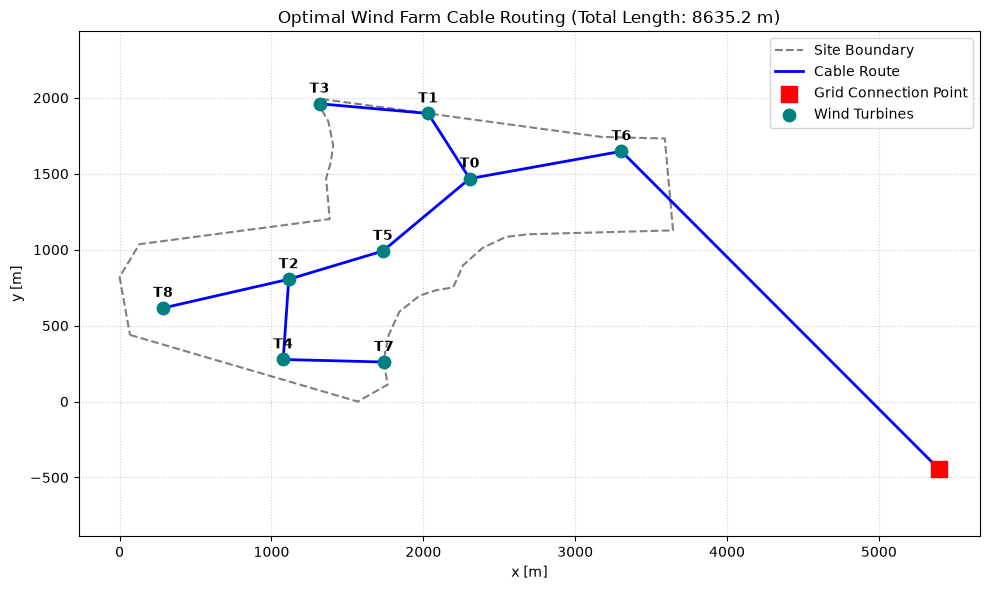


Fichier 'wind_farm_layout.kml' généré avec succès !
Tu peux maintenant double-cliquer sur ce fichier dans ton explorateur Windows pour l'ouvrir dans Google Earth.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Proj
from scipy.spatial.distance import cdist
from scipy.sparse.csgraph import minimum_spanning_tree

# --- 1. RECREATE SITE ORIGIN (from your KML setup) ---
coords_text = """
1.206860519027202,51.36446385128804,0 1.228540535625071,51.36084646145472,0 1.231326914666149,51.36188554554997,0 1.230900428385338,51.36335221424344,0 1.231327805526934,51.36484423631089,0 1.232271635958224,51.36622022749638,0 1.234157153928741,51.36720473911184,0 1.235699875038621,51.36754714218748,0 1.237311169556172,51.36773970677682,0 1.23816843336801,51.36904525549213,0 1.23998567737952,51.37011530661318,0 1.242180078810307,51.37080004683563,0 1.244278951540922,51.37099084556765,0 1.257965756297754,51.37142367570682,0 1.256980499819131,51.37685128614747,0 1.25101941585005,51.37685381922977,0 1.224173520164562,51.3787160209091,0 1.224263858984787,51.37828483960372,0 1.225127525628988,51.37738319886369,0 1.225643005910668,51.3759615509838,0 1.225426984561819,51.37490328765479,0 1.225044701109166,51.37401101384313,0 1.22547755707124,51.37160360959665,0 1.20754064599127,51.36984418480619,0 1.205743544487601,51.36788013238516,0 1.206860519027202,51.36446385128804,0 
"""
raw_coords = [list(map(float, c.split(',')[:2])) for c in coords_text.strip().split()]
lons = np.array([c[0] for c in raw_coords])
lats = np.array([c[1] for c in raw_coords])

proj = Proj(proj='utm', zone=31, ellps='WGS84', datum='WGS84')
x_utm, y_utm = proj(lons, lats)
x_origin, y_origin = x_utm.min(), y_utm.min()
site_boundary_vertices = np.column_stack((x_utm - x_origin, y_utm - y_origin))

# --- 2. CONVERT CONNECTION POINT TO LOCAL (x, y) ---
conn_lon, conn_lat = 1.28364722, 51.35766389
conn_x_utm, conn_y_utm = proj(conn_lon, conn_lat)
conn_point = np.array([[conn_x_utm - x_origin, conn_y_utm - y_origin]])

# --- 3. INPUT TURBINE COORDINATES (Dynamic size) ---
# You can replace this directly with np.column_stack((state['x'], state['y']))
turbine_data = [
    [2305.186085, 1468.046187],
    [2031.822575, 1897.085894],
    [1113.943931,  805.266416],
    [1316.484154, 1961.013958],
    [1077.334510,  277.085224],
    [1733.768614,  991.380238],
    [3304.858701, 1647.977214],
    [1741.182846,  260.270470],
    [ 286.265609,  616.127904]
]
turbines_xy = np.array(turbine_data)

# --- 4. COMPUTE OPTIMAL CABLE ROUTING (Minimum Spanning Tree) ---
# Node 0 is the connection point; Nodes 1 to N are Turbines 0 to N-1
all_nodes = np.vstack((conn_point, turbines_xy))
node_labels = ["Substation / Point"] + [f"Turbine {i}" for i in range(len(turbines_xy))]

# Pairwise Euclidean distance matrix between all points
dist_matrix = cdist(all_nodes, all_nodes, metric='euclidean')

# Compute the Minimum Spanning Tree
mst = minimum_spanning_tree(dist_matrix)
mst_array = mst.toarray()

# Extract cable segments and compute total length
connections = np.argwhere(mst_array > 0)
total_cable_length = mst_array.sum()

print(f"=== OPTIMAL CABLE ROUTING RESULTS ===")
print(f"Connection point local coords: x = {conn_point[0,0]:.2f} m, y = {conn_point[0,1]:.2f} m")
print(f"Total Optimal Cable Length: {total_cable_length:.2f} meters ({total_cable_length/1000:.3f} km)\n")
print("Cable Segments:")
for idx_from, idx_to in connections:
    length = mst_array[idx_from, idx_to]
    print(f"  - {node_labels[idx_from]} <---> {node_labels[idx_to]} : {length:.2f} m")

# --- 5. PLOT THE CABLE LAYOUT ---
plt.figure(figsize=(10, 6))

# Plot site boundary
plt.plot(site_boundary_vertices[:, 0], site_boundary_vertices[:, 1], 'k--', alpha=0.5, label='Site Boundary')

# Plot cable connections
for i, (idx_from, idx_to) in enumerate(connections):
    p1 = all_nodes[idx_from]
    p2 = all_nodes[idx_to]
    plt.plot([p1[0], p2[0]], [p1[1], p2[1]], 'b-', linewidth=2, label='Cable Route' if i == 0 else "")

# Plot connection point and turbines
plt.scatter(conn_point[:, 0], conn_point[:, 1], color='red', s=120, marker='s', zorder=5, label='Grid Connection Point')
plt.scatter(turbines_xy[:, 0], turbines_xy[:, 1], color='teal', s=80, zorder=5, label='Wind Turbines')

# Annotate turbine numbers
for i, (x, y) in enumerate(turbines_xy):
    plt.annotate(f"T{i}", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontweight='bold')

plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title(f'Optimal Wind Farm Cable Routing (Total Length: {total_cable_length:.1f} m)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.axis('equal')
plt.tight_layout()
plt.show()


# --- 6. UNCOMMENT TO EXPORT TO GOOGLE EARTH (KML FORMAT) ---

# # Convert all local nodes (connection + turbines) back to real GPS (Lon, Lat)
# all_nodes_lon, all_nodes_lat = proj(all_nodes[:, 0] + x_origin, all_nodes[:, 1] + y_origin, inverse=True)

# # Start building the KML text
# kml_content = '<?xml version="1.0" encoding="UTF-8"?>\n'
# kml_content += '<kml xmlns="http://www.opengis.net/kml/2.2">\n<Document>\n'
# kml_content += '  <name>Wind Farm Layout</name>\n'

# # Add points (Turbines and Substation)
# for i in range(len(all_nodes_lon)):
#     lon, lat = all_nodes_lon[i], all_nodes_lat[i]
#     name = "Substation" if i == 0 else f"Turbine {i-1}"
#     color = "ff0000ff" if i == 0 else "ff00aaff" # Red for substation, Orange for turbines
    
#     kml_content += f'''
#     <Placemark>
#       <name>{name}</name>
#       <Point>
#         <coordinates>{lon},{lat},0</coordinates>
#       </Point>
#     </Placemark>'''

# # Add cables (Lines)
# for idx_from, idx_to in connections:
#     lon1, lat1 = all_nodes_lon[idx_from], all_nodes_lat[idx_from]
#     lon2, lat2 = all_nodes_lon[idx_to], all_nodes_lat[idx_to]
    
#     kml_content += f'''
#     <Placemark>
#       <name>Cable</name>
#       <Style><LineStyle><color>ffff0000</color><width>3</width></LineStyle></Style>
#       <LineString>
#         <tessellate>1</tessellate>
#         <coordinates>{lon1},{lat1},0 {lon2},{lat2},0</coordinates>
#       </LineString>
#     </Placemark>'''

# kml_content += '\n</Document>\n</kml>'

# # Save the file
# kml_filename = "wind_farm_layout.kml"
# with open(kml_filename, 'w') as f:
#     f.write(kml_content)
